# Vehicle Insurance Cross-Sell Analysis

# 1. Business Understanding

#### Business Context

An insurance company aims to identify customers who are more likely to respond positively to a vehicle insurance cross-selling offer. By analyzing customer demographics, vehicle characteristics, insurance history, and other relevant attributes, the company seeks to identify potential customer segments for more focused marketing campaigns.

#### Business Objective

The objective of this project is to analyse customer demographics, vehicle characteristics, insurance history and policy-related attributes to understand patterns associated with positive responses to vehicle insurance cross-selling offers.

The analysis aims to:

* Identify customer segments with relatively higher observed response rates.

* Investigate relationships between customer characteristics and response behaviour.

* Develop classification models to identify potential responders.

* Evaluate model performance using metrics suitable for an imbalanced classification problem.

* Translate analytical findings into actionable recommendations for more focused marketing outreach.

The ultimate goal is to support data-driven customer prioritisation while considering campaign efficiency and the limitations of predictive modelling.

#### Analytical Approach

- Explore customer characteristics and response patterns.
- Assess data quality and prepare relevant features.
- Identify meaningful relationships through statistical analysis.
- Develop and evaluate classification models.
- Translate findings into actionable business recommendations.

# 2. Importing Libraries and Dataset Loading 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, mannwhitneyu

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

In [2]:
DATA_PATH = Path("../data/train.csv")

# Load the raw dataset
df = pd.read_csv(DATA_PATH)

print(f"Loaded {DATA_PATH.name}: {df.shape[0]:,} rows and {df.shape[1]} columns.")

Loaded train.csv: 381,109 rows and 12 columns.


In [3]:
df.head()

,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


In [4]:
print(df.shape)

(381109, 12)


In [5]:
# Inspect column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  str    
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  str    
 7   Vehicle_Damage        381109 non-null  str    
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 40.5 MB


**Check missing values**

In [6]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage (%)": (missing_values / len(df)) * 100
})

display(missing_summary)

,Missing Values,Missing Percentage (%)
id,0,0.0
Gender,0,0.0
Age,0,0.0
Driving_License,0,0.0
Region_Code,0,0.0
Previously_Insured,0,0.0
Vehicle_Age,0,0.0
Vehicle_Damage,0,0.0
Annual_Premium,0,0.0
Policy_Sales_Channel,0,0.0


**Check duplicate records**

In [7]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


**Check data types**

In [8]:
# Review data types

display(df.dtypes)

id                        int64
Gender                      str
Age                       int64
Driving_License           int64
Region_Code             float64
Previously_Insured        int64
Vehicle_Age                 str
Vehicle_Damage              str
Annual_Premium          float64
Policy_Sales_Channel    float64
Vintage                   int64
Response                  int64
dtype: object

**Understand the target variable**

In [9]:
# Summarize customer response

response_summary = pd.DataFrame({
    "Customer Count": df["Response"].value_counts().sort_index(),
    "Percentage (%)": df["Response"].value_counts(normalize=True).sort_index() * 100
})

response_summary.index = ["No Positive Response (0)", "Positive Response (1)"]

display(response_summary.round(2))

,Customer Count,Percentage (%)
No Positive Response (0),334399,87.74
Positive Response (1),46710,12.26


Only 12.26% of customers responded positively to the vehicle insurance offer, while 87.74% did not.

This indicates a class imbalance: positive responses are much less common than negative responses.

Why this matters:
- A campaign aimed at every customer may have limited effectiveness.
- Accuracy alone may be misleading when we later evaluate machine learning models.
- We should analyze response rates by customer segment to identify potentially promising groups.
This is an observed response rate, not proof that a targeted campaign will increase sales.

# 3. Exploratory Data Analysis

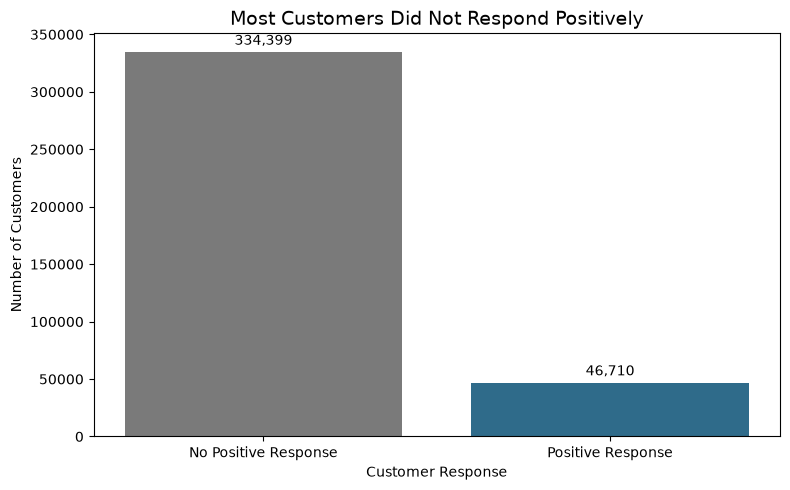

In [10]:
# Visualize the distribution of customer responses

response_labels = ["No Positive Response", "Positive Response"]
response_values = df["Response"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    response_labels,
    response_values,
    color=["#7A7A7A", "#2F6B8A"]
)

plt.title("Most Customers Did Not Respond Positively", fontsize=14)
plt.xlabel("Customer Response")
plt.ylabel("Number of Customers")

plt.bar_label(
    bars,
    labels=[f"{value:,}" for value in response_values],
    padding=3
)

plt.tight_layout()
plt.show()

**Overall Customer Response**

Only 12.26% of customers (46,710 out of 381,109) responded positively to the vehicle insurance offer, while 87.74% did not.

This indicates a substantial class imbalance, with positive responses representing a minority of the dataset. Therefore, accuracy alone may not provide a complete assessment of future classification models. Further analysis should focus on response rates across customer segments to identify groups with relatively higher observed engagement.

**Business implication:** Customer segmentation may help prioritise potential outreach opportunities. However, these observed response patterns do not establish that targeted campaigns will directly increase sales.


**Create age groups**

In [11]:
# Group customers into age segments
age_bins = [18, 25, 35, 45, 55, 65, 100]

age_labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "66+"
]

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

df[["Age", "Age_Group"]].head(10)

,Age,Age_Group
0,44,36-45
1,76,66+
2,47,46-55
3,21,18-25
4,29,26-35
5,24,18-25
6,23,18-25
7,56,56-65
8,24,18-25
9,32,26-35


**Calculate response rate by age group**

In [12]:
# Calculate customer count and positive response rate by age group

age_analysis = df.groupby("Age_Group", observed=False).agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

age_analysis["Response_Rate"] = age_analysis["Response_Rate"] * 100

display(age_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Age_Group,,,
18-25,114505,4047,3.53
26-35,72307,8198,11.34
36-45,70532,15192,21.54
46-55,61549,12123,19.70
56-65,34147,4815,14.10
66+,28069,2335,8.32


**Visualize response rate by age**

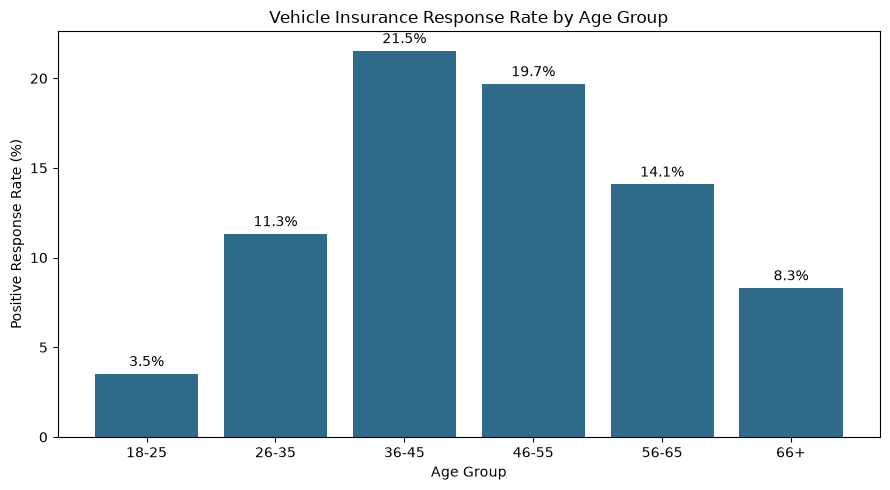

In [13]:
# Plot response rate by age group

plt.figure(figsize=(9, 5))

bars = plt.bar(
    age_analysis.index.astype(str),
    age_analysis["Response_Rate"],
    color="#2F6B8A"
)

plt.title("Vehicle Insurance Response Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in age_analysis["Response_Rate"]],
    padding=3
)

plt.tight_layout()
plt.show()


**Customer Response by Age**

Customers aged 36–45 recorded the highest positive response rate (21.54%), followed by customers aged 46–55 (19.70%). The lowest response rate was observed among customers aged 18–25 (3.53%).

Response rates increase from younger to middle-aged customers and decline among older age groups.

**Business implication:** Middle-aged customer segments may warrant further investigation for vehicle insurance campaigns. Age alone should not determine targeting; other customer characteristics and campaign performance should also be evaluated.


**Analyze previous vehicle insurance**

**Response rate by previous insurance**

In [14]:
# Analyze response based on previous vehicle insurance

previous_insurance_analysis = df.groupby("Previously_Insured").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

previous_insurance_analysis["Response_Rate"] *= 100

display(previous_insurance_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Previously_Insured,,,
0,206481,46552,22.55
1,174628,158,0.09


0 = customer was not previously insured

1 = customer was previously insured

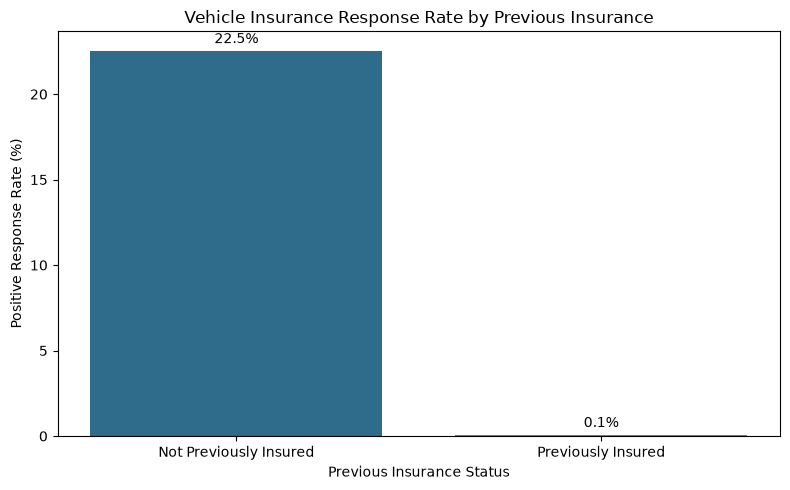

In [15]:
# Visualize response rate by previous insurance

labels = ["Not Previously Insured", "Previously Insured"]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    labels,
    previous_insurance_analysis["Response_Rate"],
    color=["#2F6B8A", "#7A7A7A"]
)

plt.title("Vehicle Insurance Response Rate by Previous Insurance")
plt.xlabel("Previous Insurance Status")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in previous_insurance_analysis["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()


**Previous Vehicle Insurance**

Customers without previous vehicle insurance recorded a positive response rate of 22.55%, compared with only 0.09% among customers who already had vehicle insurance.

This is one of the strongest differences observed so far in the customer segmentation analysis.

**Business implication:** Customers without existing vehicle insurance may represent a promising segment for cross-selling. However, this finding should be validated alongside other characteristics and campaign constraints.


**Analyze vehicle damage history**

Are customers with vehicle damage history more likely to respond positively?

In [16]:
# Analyze response based on vehicle damage history

damage_analysis = df.groupby("Vehicle_Damage").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

damage_analysis["Response_Rate"] *= 100

display(damage_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Vehicle_Damage,,,
No,188696,982,0.52
Yes,192413,45728,23.77


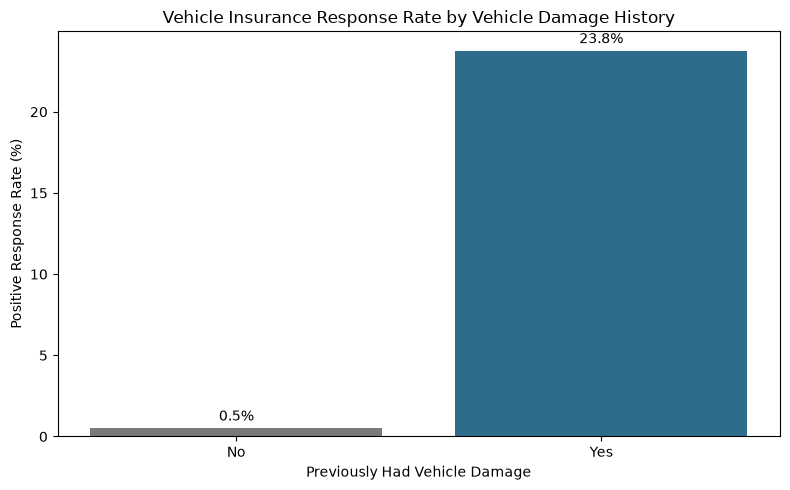

In [17]:
# Plot response rate by vehicle damage history

damage_analysis = damage_analysis.reindex(["No", "Yes"])

plt.figure(figsize=(8, 5))

bars = plt.bar(
    damage_analysis.index,
    damage_analysis["Response_Rate"],
    color=["#7A7A7A", "#2F6B8A"]
)

plt.title("Vehicle Insurance Response Rate by Vehicle Damage History")
plt.xlabel("Previously Had Vehicle Damage")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in damage_analysis["Response_Rate"]],
    padding=3
)

plt.tight_layout()
plt.show()

**Vehicle Damage History**

Customers who reported previous vehicle damage had a positive response rate of 23.77%, compared with 0.52% among customers who reported no vehicle damage.

The observed difference is substantial and suggests that vehicle damage history is strongly associated with customer response in this dataset.

**Business implication:** Customers with vehicle damage history may be a promising segment for further cross-sell analysis. This relationship should be considered alongside previous insurance status and other customer characteristics.


**Analyze vehicle age**

Does the age of a customer's vehicle relate to their response to the insurance offer?

Calculate response rate by vehicle age

In [18]:
# Analyze response based on vehicle age

vehicle_age_analysis = df.groupby("Vehicle_Age").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

vehicle_age_analysis["Response_Rate"] *= 100

# Arrange categories in a logical order
vehicle_age_analysis = vehicle_age_analysis.reindex(
    ["< 1 Year", "1-2 Year", "> 2 Years"]
)

display(vehicle_age_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Vehicle_Age,,,
< 1 Year,164786,7202,4.37
1-2 Year,200316,34806,17.38
> 2 Years,16007,4702,29.37


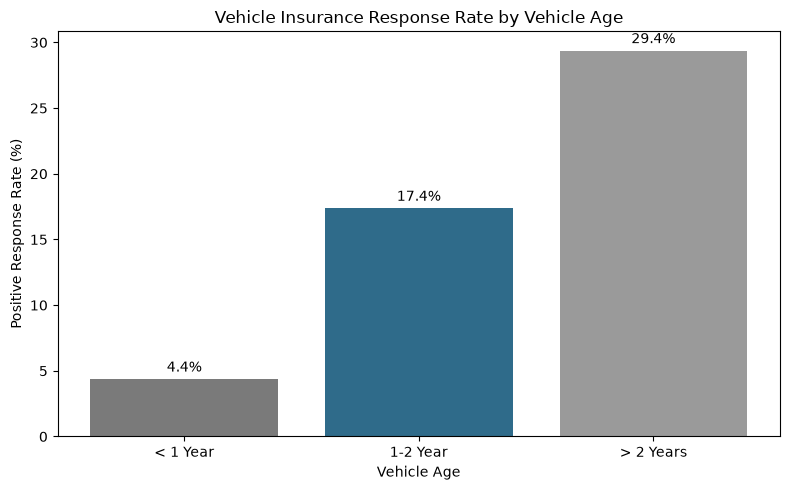

In [19]:
# Plot response rate by vehicle age

plt.figure(figsize=(8, 5))

bars = plt.bar(
    vehicle_age_analysis.index,
    vehicle_age_analysis["Response_Rate"],
    color=["#7A7A7A", "#2F6B8A", "#9A9A9A"]
)

plt.title("Vehicle Insurance Response Rate by Vehicle Age")
plt.xlabel("Vehicle Age")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in vehicle_age_analysis["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()

**Vehicle Age**

Customers with vehicles older than 2 years recorded the highest positive response rate (29.37%), followed by customers with vehicles aged 1–2 years (17.38%). Customers with vehicles less than 1 year old had the lowest response rate (4.37%).

**Business implication:** Vehicle age may be a useful factor for customer segmentation. Customers with older vehicles could be investigated further as a potential cross-sell segment. However, the group with vehicles older than 2 years is comparatively small, and this association does not establish causality.


**Analyze annual premium**

In [20]:
# Summarize annual premium by response

premium_analysis = df.groupby("Response")["Annual_Premium"].agg(
    ["count", "mean", "median", "min", "max"]
)

premium_analysis.index = [
    "No Positive Response",
    "Positive Response"
]

display(premium_analysis.round(2))

,count,mean,median,min,max
No Positive Response,334399,30419.16,31504.0,2630.0,540165.0
Positive Response,46710,31604.09,33002.0,2630.0,540165.0


Customers who responded positively had a higher mean annual premium: 31,604.09 versus 30,419.16.



Their median premium was also higher: 33,002 versus 31,504.



Both groups have the same reported minimum and maximum.

**Visualize annual premium distribution**

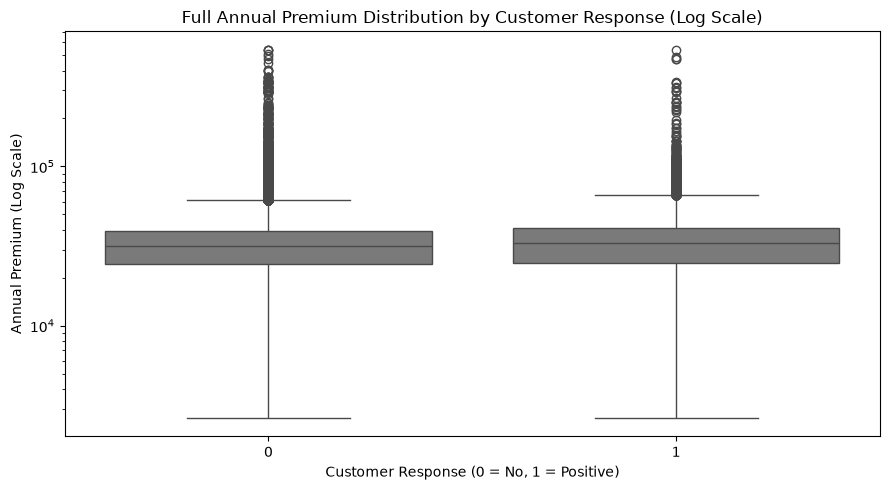

In [21]:
# Compare the full annual premium distributions by customer response

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Response",
    y="Annual_Premium",
    color="#7A7A7A"
)

plt.yscale("log")
plt.title("Full Annual Premium Distribution by Customer Response (Log Scale)")
plt.xlabel("Customer Response (0 = No, 1 = Positive)")
plt.ylabel("Annual Premium (Log Scale)")

plt.tight_layout()
plt.show()


The full annual premium distributions show broadly similar patterns for customers who responded positively and those who did not. Responders appear to have a slightly higher median premium, while both groups contain numerous high-value outliers.

The substantial overlap between the distributions suggests that annual premium alone may have limited ability to distinguish potential responders from non-responders.

Business implication: Annual premium may provide supporting information for customer segmentation, but it should be considered alongside stronger indicators such as previous insurance status, vehicle damage history, and vehicle age.

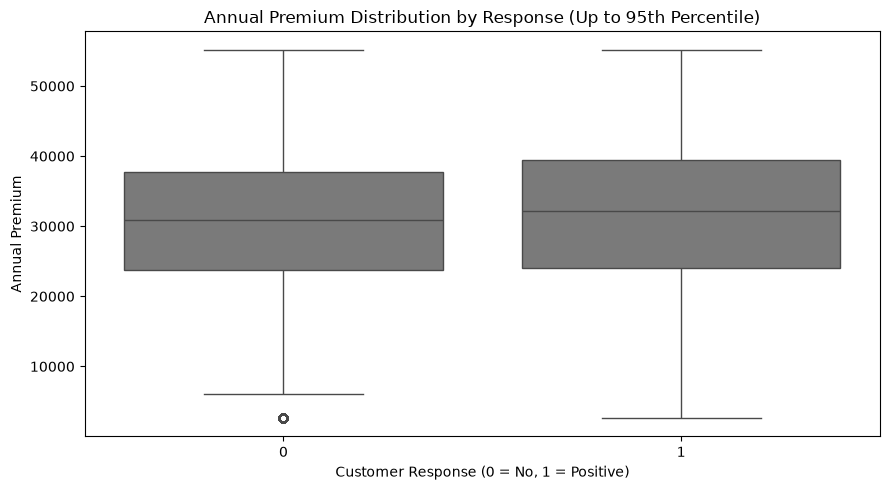

In [22]:
# Calculate the 95th percentile for visualization
premium_95th = df["Annual_Premium"].quantile(0.95)

# Plot the premium distribution below the 95th percentile
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df[df["Annual_Premium"] <= premium_95th],
    x="Response",
    y="Annual_Premium",
    color="#7A7A7A"
)

plt.title("Annual Premium Distribution by Response (Up to 95th Percentile)")
plt.xlabel("Customer Response (0 = No, 1 = Positive)")
plt.ylabel("Annual Premium")

plt.tight_layout()
plt.show()

The full distribution shows the overall spread of annual premiums across both response groups, including extreme values. Since these high values can compress the central portion of the plot, a second boxplot is presented after excluding observations above the 95th percentile. This provides a clearer view of the typical premium distribution. The 95th-percentile plot is used only for visualisation; no observations are removed from the dataset.

**Sales channel analysis**

In [23]:
# Check the number of unique sales channels
df["Policy_Sales_Channel"].nunique()

155

**Response rates by sales channel**

In [25]:
# Calculate customer count and response rate for each sales channel

channel_analysis = df.groupby("Policy_Sales_Channel").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

channel_analysis["Response_Rate"] *= 100

# Select the 10 most common channels by customer volume
top_10_channels = channel_analysis.nlargest(10, "Customer_Count")

display(top_10_channels.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Policy_Sales_Channel,,,
152.0,134784,3858,2.86
26.0,79700,15891,19.94
124.0,73995,13996,18.91
160.0,21779,475,2.18
156.0,10661,2297,21.55
122.0,9930,1720,17.32
157.0,6684,1794,26.84
154.0,5993,1474,24.60
151.0,3885,122,3.14


**Visualize response rates for the top 10 channels**

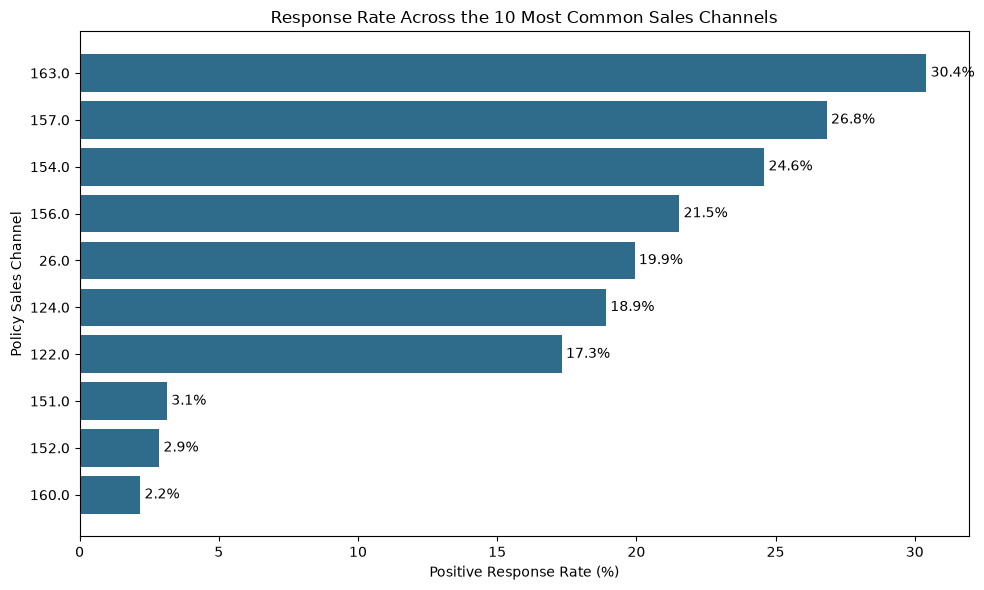

In [26]:
# Sort selected channels by response rate for easier comparison

top_10_response = top_10_channels.sort_values("Response_Rate")

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_10_response.index.astype(str),
    top_10_response["Response_Rate"],
    color="#2F6B8A"
)

plt.title("Response Rate Across the 10 Most Common Sales Channels")
plt.xlabel("Positive Response Rate (%)")
plt.ylabel("Policy Sales Channel")

plt.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in top_10_response["Response_Rate"]],
    padding=3
)

plt.tight_layout()
plt.show()

**Policy Sales Channel**

Response rates varied substantially across the 10 most common policy sales channels. Channel 163 recorded the highest response rate (30.42%), while channel 160 recorded the lowest (2.18%).

Channel 152 had the largest customer volume (134,784) but a relatively low response rate of 2.86%. In contrast, channel 26 reached 79,700 customers and achieved a 19.94% response rate.

**Business implication:** Sales channel may be an important factor in understanding customer response. Channel performance should be evaluated using both customer volume and response rate. Channel IDs are categorical identifiers, and their underlying meaning is not available in this dataset.


**Analyze Response rate by gender**

In [27]:
# Calculate response rate by gender

gender_analysis = df.groupby("Gender").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

gender_analysis["Response_Rate"] *= 100

display(gender_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Gender,,,
Female,175020,18185,10.39
Male,206089,28525,13.84


Male customers had a positive response rate of 13.84%.

Female customers had a positive response rate of 10.39%.

The observed difference is 3.45 percentage points.

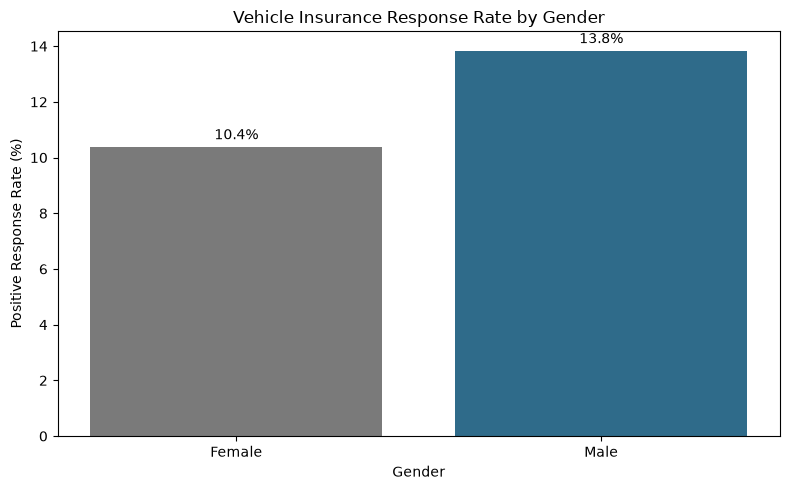

In [28]:
# Plot response rate by gender

gender_analysis = gender_analysis.reindex(["Female", "Male"])

plt.figure(figsize=(8, 5))

bars = plt.bar(
    gender_analysis.index,
    gender_analysis["Response_Rate"],
    color=["#7A7A7A", "#2F6B8A"]
)

plt.title("Vehicle Insurance Response Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in gender_analysis["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()

**Customer Response by Gender**

Male customers recorded a positive response rate of 13.84%, compared with 10.39% among female customers. The observed difference was 3.45 percentage points.

**Business implication:** Gender shows a response-rate difference in this dataset, but it should be evaluated alongside other customer characteristics. This descriptive result does not establish causality or justify gender-based targeting on its own.


**Analyze response by region**

In [29]:
# Check the number of unique regions
df["Region_Code"].nunique()

53

Response rate by region

In [30]:
# Calculate customer count and response rate by region

region_analysis = df.groupby("Region_Code").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

region_analysis["Response_Rate"] *= 100

# Select the 10 regions with the highest customer volume
top_10_regions = region_analysis.nlargest(10, "Customer_Count")

display(top_10_regions.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Region_Code,,,
28.0,106415,19917,18.72
8.0,33877,3257,9.61
46.0,19749,2032,10.29
41.0,18263,2224,12.18
15.0,13308,958,7.20
30.0,12191,900,7.38
29.0,11065,1365,12.34
50.0,10243,642,6.27
3.0,9251,1181,12.77


Region 28 has the highest response rate among the 10 most common regions: 18.72%.

Region 28 also has the largest customer count.

Region 50 has the lowest response rate in this group: 6.27%.

Response rates vary substantially across these regions.

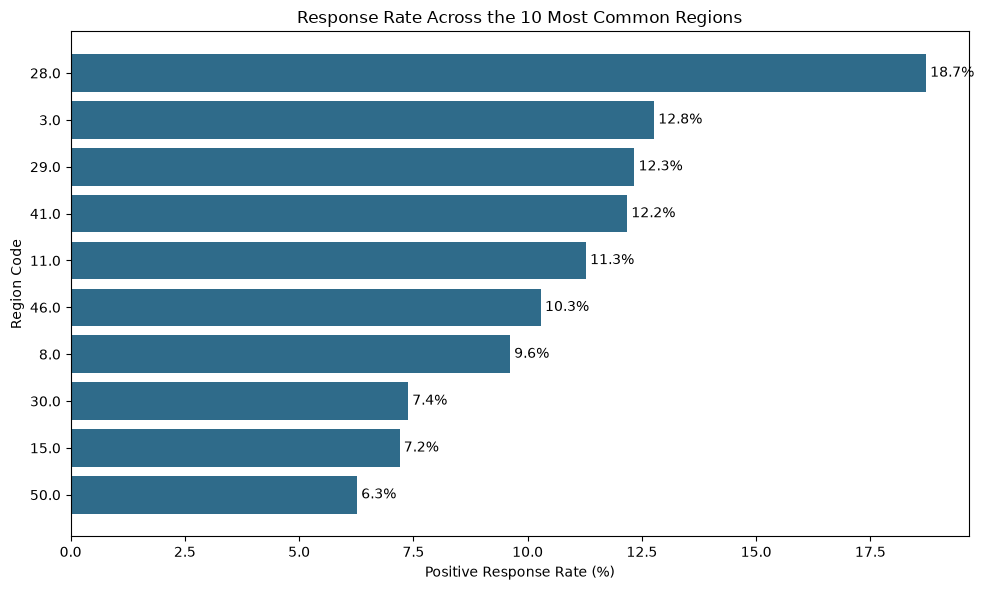

In [31]:
# Sort regions by response rate

top_10_region_rates = top_10_regions.sort_values("Response_Rate")

plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_10_region_rates.index.astype(str),
    top_10_region_rates["Response_Rate"],
    color="#2F6B8A"
)

plt.title("Response Rate Across the 10 Most Common Regions")
plt.xlabel("Positive Response Rate (%)")
plt.ylabel("Region Code")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in top_10_region_rates["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()

**Regional Response**

Response rates varied across the 10 most common regions. Region 28 recorded the highest response rate (18.72%) and the largest customer volume (106,415), while Region 50 recorded the lowest response rate (6.27%).

**Business implication:** Region codes may help identify differences in customer response. Further investigation is needed before drawing geographic conclusions, because the dataset does not provide descriptive names for the regions.


**Analyze driving license status**

In [32]:
df["Driving_License"].value_counts().sort_index()

Driving_License
0       812
1    380297
Name: count, dtype: int64

**response rates by driving-license status**

In [33]:
# Calculate response rate by driving-license status

license_analysis = df.groupby("Driving_License").agg(
    Customer_Count=("Response", "count"),
    Positive_Responses=("Response", "sum"),
    Response_Rate=("Response", "mean")
)

license_analysis["Response_Rate"] *= 100

display(license_analysis.round(2))

,Customer_Count,Positive_Responses,Response_Rate
Driving_License,,,
0,812,41,5.05
1,380297,46669,12.27


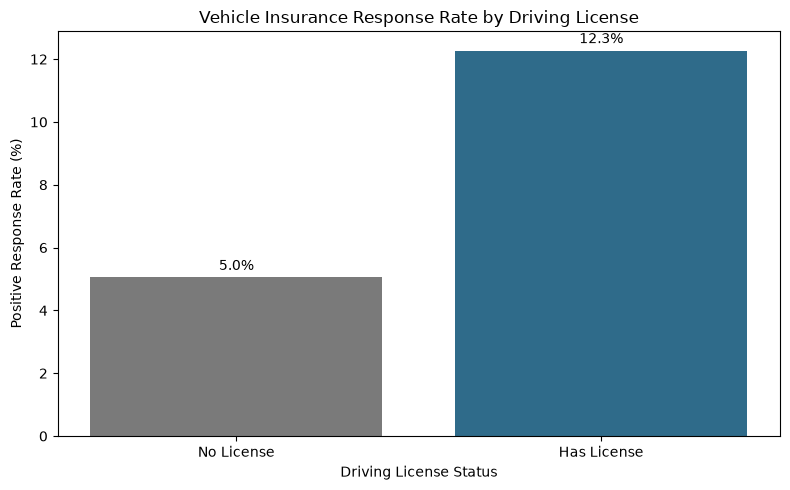

In [34]:
# Plot response rate by driving-license status

license_analysis = license_analysis.reindex([0, 1])

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["No License", "Has License"],
    license_analysis["Response_Rate"],
    color=["#7A7A7A", "#2F6B8A"]
)

plt.title("Vehicle Insurance Response Rate by Driving License")
plt.xlabel("Driving License Status")
plt.ylabel("Positive Response Rate (%)")

plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in license_analysis["Response_Rate"]
    ],
    padding=3
)

plt.tight_layout()
plt.show()


Customers with a driving license recorded a positive response rate of 12.27%, compared with 5.05% among customers without a license.

However, only 812 customers (0.21% of the dataset) did not have a driving license. The imbalance in group sizes should be considered when interpreting this comparison.

**Business implication:** Driving-license status may provide some information about response, but its limited variation in this dataset may reduce its usefulness for customer segmentation.


Analyze customer vintage
Vintage represents how long the customer has been associated with the company, measured in days in this dataset.

In [35]:
# Summary statistics for customer vintage

df["Vintage"].describe().round(2)

count    381109.00
mean        154.35
std          83.67
min          10.00
25%          82.00
50%         154.00
75%         227.00
max         299.00
Name: Vintage, dtype: float64

In [36]:
# Compare customer vintage by response

vintage_analysis = df.groupby("Response")["Vintage"].agg(
    ["count", "mean", "median", "min", "max"]
)

vintage_analysis.index = [
    "No Positive Response",
    "Positive Response"
]

display(vintage_analysis.round(2))

,count,mean,median,min,max
No Positive Response,334399,154.38,154.0,10,299
Positive Response,46710,154.11,154.0,10,299



The mean customer vintage was 154.38 days among customers who did not respond positively and 154.11 days among positive responders. Both groups had a median vintage of 154 days.

The distributions appear similar based on these summary statistics.

**Business implication:** Customer vintage alone may have limited descriptive value for distinguishing positive responders from non-responders. Its usefulness should be evaluated alongside other features.



#### EDA Summary

#### Overview
The dataset contains 381,109 customer records and 12 columns. No missing values or exact duplicate rows were identified during the initial data-quality audit.

The overall positive response rate to the vehicle insurance offer was 12.26%.

#### Key Findings
- Customers aged 36–45 recorded the highest response rate among the age groups analyzed (21.54%).
- Customers without previous vehicle insurance had a response rate of 22.55%.
- Customers with vehicle damage history had a response rate of 23.77%.
- Customers with vehicles older than 2 years had a response rate of 29.37%.
- Response rates varied substantially across sales channels and regions.
- Male customers had a response rate of 13.84%, compared with 10.39% for female customers.
- Annual premium distributions overlapped considerably between response groups.
- Customer vintage statistics were similar for positive responders and non-responders.

#### Limitations
- The analysis is observational and does not establish causality.
- The dataset contains an imbalanced target variable.
- Sales channel and region codes lack descriptive labels.
- Segment-level response rates do not guarantee future campaign performance.


Further data validation, feature analysis, and statistical investigation will be performed before predictive modeling.



Create a working dataset
# 4. Data Cleaning and Validation

In this section, a separate working copy of the original dataset will be created.

## 4.1 The original dataset will remain unchanged to preserve data integrity and allow reproducibility.


In [37]:
# Load the original dataset
df = pd.read_csv("../data/train.csv")

# Preserve an untouched copy
df_raw = df.copy()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [38]:
df_clean = df.copy()

In [39]:
# Check missing values in each column
print("Missing values:")
print(df_clean.isnull().sum())

# Check exact duplicate rows
print("\nDuplicate rows:", df_clean.duplicated().sum())

# Check duplicate customer IDs
print("Duplicate IDs:", df_clean["id"].duplicated().sum())

Missing values:
id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64

Duplicate rows: 0
Duplicate IDs: 0


**Validate categorical values**

In [40]:
# Check unique values in categorical columns

categorical_columns = [
    "Gender",
    "Driving_License",
    "Previously_Insured",
    "Vehicle_Age",
    "Vehicle_Damage",
    "Response"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df_clean[column].value_counts())


Gender:
Gender
Male      206089
Female    175020
Name: count, dtype: int64

Driving_License:
Driving_License
1    380297
0       812
Name: count, dtype: int64

Previously_Insured:
Previously_Insured
0    206481
1    174628
Name: count, dtype: int64

Vehicle_Age:
Vehicle_Age
1-2 Year     200316
< 1 Year     164786
> 2 Years     16007
Name: count, dtype: int64

Vehicle_Damage:
Vehicle_Damage
Yes    192413
No     188696
Name: count, dtype: int64

Response:
Response
0    334399
1     46710
Name: count, dtype: int64


**Check numerical ranges and target values**

In [41]:
# Check numerical columns for unexpected ranges

numerical_columns = [
    "Age",
    "Region_Code",
    "Annual_Premium",
    "Policy_Sales_Channel",
    "Vintage"
]

df_clean[numerical_columns].describe()

,Age,Region_Code,Annual_Premium,Policy_Sales_Channel,Vintage
count,381109.000000,381109.000000,381109.000000,381109.000000,381109.000000
mean,38.822584,26.388807,30564.389581,112.034295,154.347397
std,15.511611,13.229888,17213.155057,54.203995,83.671304
min,20.000000,0.000000,2630.000000,1.000000,10.000000
25%,25.000000,15.000000,24405.000000,29.000000,82.000000
50%,36.000000,28.000000,31669.000000,133.000000,154.000000
75%,49.000000,35.000000,39400.000000,152.000000,227.000000
max,85.000000,52.000000,540165.000000,163.000000,299.000000


Age: 20–85 years — plausible range for this dataset.

Region_Code: 0–52 — numeric codes, categorical in meaning.

Annual_Premium: ₹2,630–₹540,165 — maximum is much higher than the 75th percentile (₹39,400), so there are extreme values to investigate.

Policy_Sales_Channel: 1–163 — category codes, not continuous measurements.

Vintage: 10–299 — customer tenure values; no negative values.

In [42]:
# Calculate IQR-based outlier boundaries for Annual_Premium

Q1 = df_clean["Annual_Premium"].quantile(0.25)
Q3 = df_clean["Annual_Premium"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_clean[
    (df_clean["Annual_Premium"] < lower_bound) |
    (df_clean["Annual_Premium"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))
print("Outlier percentage:", round(len(outliers) / len(df_clean) * 100, 2), "%")

Q1: 24405.0
Q3: 39400.0
IQR: 14995.0
Lower bound: 1912.5
Upper bound: 61892.5
Number of outliers: 10320
Outlier percentage: 2.71 %


10,320 records have annual premiums above the IQR upper boundary of 61,892.50. There are no lower-bound outliers because the minimum premium is 2,630.

These are statistical outliers, not necessarily data errors. Since the dataset has no missing values or duplicates and the premiums are positive, we should preserve the original records for now.

**Check binary variables and ID integrity**

In [43]:
# Validate binary columns
binary_columns = [
    "Driving_License",
    "Previously_Insured",
    "Response"
]

for column in binary_columns:
    print(f"{column}: {sorted(df_clean[column].unique())}")

# Check ID range
print("\nID minimum:", df_clean["id"].min())
print("ID maximum:", df_clean["id"].max())
print("Unique IDs:", df_clean["id"].nunique())

Driving_License: [np.int64(0), np.int64(1)]
Previously_Insured: [np.int64(0), np.int64(1)]
Response: [np.int64(0), np.int64(1)]

ID minimum: 1
ID maximum: 381109
Unique IDs: 381109


## 4.2 Validation Summary

### Objective
Validate the original dataset's structure, completeness, uniqueness, categorical values, numerical ranges, and potential outliers before proceeding to feature engineering or modeling.

### Validation Results
- Dataset contains **381,109 rows and 12 columns**.
- No missing values were detected.
- No duplicate rows were detected.
- No duplicate customer IDs were detected.
- Customer IDs range from 1 to 381,109, with all IDs unique.
- Binary columns (`Driving_License`, `Previously_Insured`, and `Response`) contain only 0 and 1.
- Categorical columns (`Gender`, `Vehicle_Age`, and `Vehicle_Damage`) contain expected categories.
- Numerical ranges were reviewed using descriptive statistics.
- The IQR method identified **10,320 Annual_Premium observations (2.71%)** above the upper boundary of 61,892.50.

### Cleaning Decisions
No rows were removed or values imputed because the dataset contained no missing values or duplicates.

Potential Annual_Premium outliers were retained because statistical outliers are not necessarily invalid records. They will be considered during further analysis and modeling.

### Conclusion
The dataset passed the initial structural and data-quality checks. It is suitable for continued exploratory analysis and preparation, subject to appropriate feature validation and preprocessing in later stages.

## 4.3 Feature Engineering

**Create an age-group feature**

In [44]:
# Create age groups for customer segmentation

age_bins = [18, 25, 35, 45, 55, 65, 100]

age_labels = [
    "18-25",
    "26-35",
    "36-45",
    "46-55",
    "56-65",
    "66+"
]

df_clean["Age_Group"] = pd.cut(
    df_clean["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

df_clean[["Age", "Age_Group"]].head(10)

,Age,Age_Group
0,44,36-45
1,76,66+
2,47,46-55
3,21,18-25
4,29,26-35
5,24,18-25
6,23,18-25
7,56,56-65
8,24,18-25
9,32,26-35


**Validate the new feature**

In [45]:
# Check age-group counts and missing values

print(df_clean["Age_Group"].value_counts().sort_index())

print("\nMissing Age_Group values:",
      df_clean["Age_Group"].isnull().sum())

Age_Group
18-25    114505
26-35     72307
36-45     70532
46-55     61549
56-65     34147
66+       28069
Name: count, dtype: int64

Missing Age_Group values: 0


**Create a business-focused feature**

In [46]:
# Create premium categories based on quartiles

df_clean["Premium_Category"] = pd.qcut(
    df_clean["Annual_Premium"],
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

df_clean["Premium_Category"].value_counts().sort_index()

Premium_Category
Low          95283
Medium       95286
High         95263
Very High    95277
Name: count, dtype: int64

**Validate the engineered features together**

In [47]:
# Check the engineered features

print("Age_Group missing:", df_clean["Age_Group"].isnull().sum())
print("Premium_Category missing:", df_clean["Premium_Category"].isnull().sum())

print("\nUpdated dataset shape:", df_clean.shape)

df_clean[["Age", "Age_Group", "Annual_Premium", "Premium_Category"]].head()

Age_Group missing: 0
Premium_Category missing: 0

Updated dataset shape: (381109, 14)


,Age,Age_Group,Annual_Premium,Premium_Category
0,44,36-45,40454.0,Very High
1,76,66+,33536.0,High
2,47,46-55,38294.0,High
3,21,18-25,28619.0,Medium
4,29,26-35,27496.0,Medium


**4.3 Feature Engineering Summary**

Two additional features were created to support exploratory data analysis:

1. **Age_Group:** Customers were grouped into six age categories: 18–25, 26–35, 36–45, 46–55, 56–65, and 66+.
2. **Premium_Category:** Annual premiums were divided into four categories: Low, Medium, High, and Very High, based on quartiles.

The original `Age` and `Annual_Premium` columns were retained in the dataset.

**Important modeling consideration:** `Age_Group` and `Premium_Category` are currently used for exploratory analysis only. Both engineered features are excluded from the model input, while the original numerical features (`Age` and `Annual_Premium`) are retained for model training.

The premium-category boundaries are relative to the dataset distribution. If `Premium_Category` is used as a predictive feature in a future modeling workflow, its boundaries must be calculated using the training data only and then applied to validation and test data to prevent data leakage.


## 4.4 Business Questions and Analytical Insights

### Business Objective
Identify customer segments with higher likelihood of responding to a vehicle insurance cross-selling offer. The analysis aims to support more focused marketing campaigns and improve customer targeting.

### Key Business Questions
1. Which age groups show higher response rates?
2. How does previous insurance status relate to customer response?
3. Are customers reporting vehicle damage more likely to respond?
4. Does vehicle age influence observed response patterns?
5. Which policy sales channels have higher response rates?
6. How does annual premium differ between responders and non-responders?
7. Which customer characteristics are most associated with response?

### Analytical Approach
- Compare response rates across customer segments.
- Examine both customer counts and response percentages.
- Consider sample sizes when interpreting segment results.
- Distinguish descriptive associations from causal conclusions.
- Avoid treating observed patterns as proof that a feature causes customer response.

### Business Context
The findings may help identify promising customer segments for future campaign testing. Recommendations will be based on observed patterns and should be validated through controlled marketing experiments before implementation.

**Response rate by customer segment**

In [48]:
def response_summary(data, group_column):
    summary = (
        data.groupby(group_column, observed=True)["Response"]
        .agg(
            Customers="count",
            Responders="sum",
            Response_Rate="mean"
        )
        .reset_index()
    )

    summary["Response_Rate"] = (
        summary["Response_Rate"] * 100
    ).round(2)

    return summary.sort_values(
        "Response_Rate",
        ascending=False
    )

In [49]:
# Response rate by age group

age_response = response_summary(
    df_clean,
    "Age_Group"
)

age_response

,Age_Group,Customers,Responders,Response_Rate
2,36-45,70532,15192,21.54
3,46-55,61549,12123,19.70
4,56-65,34147,4815,14.10
1,26-35,72307,8198,11.34
5,66+,28069,2335,8.32
0,18-25,114505,4047,3.53


Customers aged 36–45 have the highest response rate at 21.54%, while customers aged 18–25 have the lowest at 3.53%.

The response rate difference is:
\[
21.54\%-3.53\%=18.01 \text{ percentage points}
\]

**Age-Based Customer Response**

Customer response rates vary across age groups. Customers aged 36–45 recorded the highest response rate at 21.54%, followed by the 46–55 group at 19.70%. Customers aged 18–25 recorded the lowest rate at 3.53%. The difference between the highest and lowest groups was 18.01 percentage points. Age segmentation may help identify customer groups for further campaign evaluation, although these descriptive differences do not establish causation.

**Response rate by previous insurance status**

In [50]:
previous_insurance_response = response_summary(
    df_clean,
    "Previously_Insured"
)

previous_insurance_response

,Previously_Insured,Customers,Responders,Response_Rate
0,0,206481,46552,22.55
1,1,174628,158,0.09


Customers without previous vehicle insurance have a response rate of 22.55%, compared with just 0.09% among previously insured customers. This substantial difference indicates that customers without existing vehicle insurance are a particularly relevant segment for cross-selling campaigns.

**Response rate by vehicle damage**

In [51]:
vehicle_damage_response = response_summary(
    df_clean,
    "Vehicle_Damage"
)

vehicle_damage_response

,Vehicle_Damage,Customers,Responders,Response_Rate
1,Yes,192413,45728,23.77
0,No,188696,982,0.52


**Vehicle Damage and Customer Response**

Customers reporting previous vehicle damage have a response rate of 23.77%, compared with 0.52% among customers reporting no vehicle damage. This is a strong observed association and may help identify customer segments with greater interest in vehicle insurance.

**Response rate by vehicle age**

In [52]:
vehicle_age_response = response_summary(
    df_clean,
    "Vehicle_Age"
)

vehicle_age_response

,Vehicle_Age,Customers,Responders,Response_Rate
2,> 2 Years,16007,4702,29.37
0,1-2 Year,200316,34806,17.38
1,< 1 Year,164786,7202,4.37


Customers with vehicles older than two years have the highest response rate at 29.37%, followed by customers with vehicles aged 1–2 years at 17.38%. Customers with vehicles younger than one year have the lowest response rate at 4.37%. The older-vehicle segment may therefore deserve further attention in campaign planning.

**Response rate by policy sales channel**

In [53]:
# Find the 10 most frequent policy sales channels
top_channels = df_clean["Policy_Sales_Channel"].value_counts().head(10).index

channel_data = df_clean[
    df_clean["Policy_Sales_Channel"].isin(top_channels)
]

channel_response = response_summary(
    channel_data,
    "Policy_Sales_Channel"
)

channel_response

,Policy_Sales_Channel,Customers,Responders,Response_Rate
9,163.0,2893,880,30.42
7,157.0,6684,1794,26.84
5,154.0,5993,1474,24.60
6,156.0,10661,2297,21.55
0,26.0,79700,15891,19.94
2,124.0,73995,13996,18.91
1,122.0,9930,1720,17.32
3,151.0,3885,122,3.14
4,152.0,134784,3858,2.86
8,160.0,21779,475,2.18


**Policy Sales Channel Performance**

Response rates varied substantially across the ten most frequent policy sales channels. Channel 163 recorded the highest response rate (30.42%), while Channel 160 had the lowest (2.18%) among these channels. Channel 26 generated the largest number of responders (15,891), despite having a lower response rate than several smaller channels. This highlights the importance of evaluating both response rate and customer volume when assessing channel performance.

These findings are descriptive. Channel codes are identifiers, and their operational meaning cannot be inferred without channel documentation.

**Annual Premium vs. Response**

In [54]:
premium_response_summary = (
    df_clean.groupby("Response")["Annual_Premium"]
    .agg(
        Customers="count",
        Mean_Premium="mean",
        Median_Premium="median"
    )
    .round(2)
)

premium_response_summary

,Customers,Mean_Premium,Median_Premium
Response,,,
0,334399,30419.16,31504.0
1,46710,31604.09,33002.0


**Annual Premium and Customer Response**

Responders had a higher average annual premium (31,604.09) than non-responders (30,419.16). The median premium was also higher among responders (33,002 compared with 31,504). However, the difference was modest relative to the overall premium variation. Annual premium may provide some descriptive insight into response behavior, but it should not be treated as a strong standalone targeting factor without further analysis.

**Consolidated business insights table**

In [106]:
business_insights = pd.DataFrame({
    "Business_Factor": [
        "Age Group",
        "Previously Insured",
        "Vehicle Damage",
        "Vehicle Age",
        "Policy Sales Channel",
        "Annual Premium"
    ],
    "Key_Finding": [
        "Age 36-45 had the highest response rate (21.54%).",
        "Customers not previously insured had a 22.55% response rate.",
        "Customers reporting vehicle damage had a 23.77% response rate.",
        "Vehicles older than 2 years had a 29.37% response rate.",
        "Channel 163 had the highest response rate among the top 10 channels (30.42%).",
        "Responders had a higher median premium (33,002 vs. 31,504)."
    ],
    "Business_Implication": [
        "Evaluate middle-aged customers for campaign targeting.",
        "Investigate customers without previous insurance.",
        "Evaluate vehicle-damage history as a segmentation variable.",
        "Explore older-vehicle owners as a potential segment.",
        "Investigate high-performing channels while considering volume.",
        "Assess premium alongside other customer characteristics."
    ]
})

business_insights

,Business_Factor,Key_Finding,Business_Implication
0,Age Group,Age 36-45 had the highest response rate (21.54%).,Evaluate middle-aged customers for campaign ta...
1,Previously Insured,Customers not previously insured had a 22.55% ...,Investigate customers without previous insurance.
2,Vehicle Damage,Customers reporting vehicle damage had a 23.77...,Evaluate vehicle-damage history as a segmentat...
3,Vehicle Age,Vehicles older than 2 years had a 29.37% respo...,Explore older-vehicle owners as a potential se...
4,Policy Sales Channel,Channel 163 had the highest response rate amon...,Investigate high-performing channels while con...
5,Annual Premium,"Responders had a higher median premium (33,002...",Assess premium alongside other customer charac...


**Business Analysis Summary** 

### Summary of Findings

The exploratory analysis identified several customer characteristics associated with response to the vehicle insurance cross-selling offer:

- Customers aged 36–45 had the highest response rate among age groups (21.54%).
- Customers without previous insurance had a response rate of 22.55%, compared with 0.09% among previously insured customers.
- Customers reporting vehicle damage had a response rate of 23.77%, compared with 0.52% among customers without reported damage.
- Customers with vehicles older than two years had the highest response rate by vehicle age (29.37%).
- Policy sales channel response rates varied considerably. Channel 163 had the highest response rate among the ten most frequent channels (30.42%).
- Responders had a higher median annual premium than non-responders (33,002 compared with 31,504).

### Business Recommendations

1. Investigate customers without previous insurance as a potential cross-selling segment.
2. Evaluate vehicle damage history and vehicle age as useful customer segmentation variables.
3. Consider both response rate and customer volume when comparing sales channels.
4. Use age-group analysis to support campaign segmentation, while avoiding assumptions about individual customers.
5. Validate potential targeting strategies through controlled marketing experiments.

### Limitations

These findings describe associations within the dataset and do not establish causation. Channel codes do not reveal the underlying channel names. Response patterns should be validated on new data before operational use.

### Conclusion

The business analysis identifies previous insurance status, vehicle damage, vehicle age and customer age as useful segmentation dimensions. Customers without previous insurance and customers reporting vehicle damage show notably higher response rates. Response rates also vary across vehicle-age and age groups, while sales-channel performance differs in both response rate and customer volume. These findings can help guide customer segmentation and campaign prioritization. However, the observed relationships do not establish causation or guarantee future campaign performance.

# 5 Statistical Analysis & Insight Validation

#### 5.1 Chi-square test
First, we’ll test previous insurance status vs. customer response.
What are we testing?
- H₀ (Null hypothesis): Previous insurance status and response are independent.
- H₁ (Alternative hypothesis): Previous insurance status and response are associated.

#### 5.2 Create the contingency table

In [56]:
from scipy.stats import chi2_contingency

In [57]:
contingency = pd.crosstab(
    df_clean["Previously_Insured"],
    df_clean["Response"]
)

contingency

Response,0,1
Previously_Insured,,
0,159929,46552
1,174470,158


**Run the statistical test**

In [101]:
chi2, p_value, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", chi2)
print("P-value:", "< 0.001" if p_value < 0.001 else f"{p_value:.4g}")
print("Degrees of freedom:", dof)

Chi-square statistic: 44357.96472219977
P-value: < 0.001
Degrees of freedom: 1


**Calculate effect size (Cramér’s V)**

In [60]:
import numpy as np

n = contingency.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(contingency.shape[0] - 1,
                    contingency.shape[1] - 1))
)

print("Cramer's V:", cramers_v)

Cramer's V: 0.34116243318192124


A chi-square test of independence was conducted to examine the association between previous insurance status and customer response.

**Statistical results:**

- Chi-square statistic: 44,357.96
- Degrees of freedom: 1
- P-value: < 0.001
- Cramér’s V: 0.3412
- Exact Cramér’s V: 0.34116243318192124

The results indicate a statistically significant association between previous insurance status and customer response. The effect size suggests a meaningful association.

Customers without previous insurance had a response rate of 22.55%, compared with 0.09% among previously insured customers.

**Business implication:** Previous insurance status may be a useful variable for cross-sell customer segmentation.

**Limitation:** This analysis identifies an association, not a causal relationship.

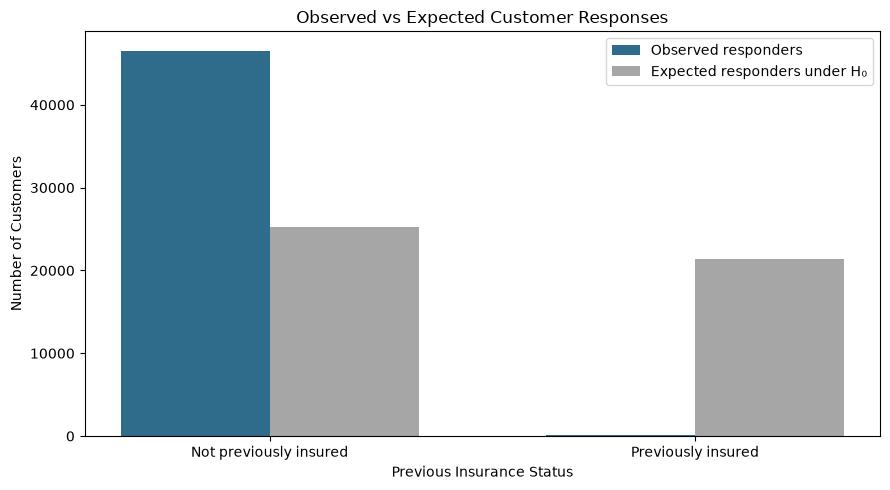

In [109]:
observed = contingency.to_numpy()
expected = chi2_contingency(contingency)[3]

labels = [
    "Not previously insured",
    "Previously insured"
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    observed[:, 1],
    width,
    label="Observed responders",
    color="#2F6B8A"
)

ax.bar(
    x + width / 2,
    expected[:, 1],
    width,
    label="Expected responders under H₀",
    color="#A6A6A6"
)

ax.set_title("Observed vs Expected Customer Responses")
ax.set_xlabel("Previous Insurance Status")
ax.set_ylabel("Number of Customers")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

plt.tight_layout()
plt.show()

Customers without previous insurance recorded 46,552 positive responses, compared with approximately 25,252 expected. Previously insured customers recorded only 158 responses, compared with approximately 21,458 expected.

This substantial difference indicates a statistically significant association between previous insurance status and customer response.

Business implication: Customers without previous insurance may be a promising segment for cross-sell campaigns.

Limitation: Association does not imply causation.

#### 5.3 Chi-square test for Vehicle Damage

Create the contingency table

In [62]:
contingency_damage = pd.crosstab(
    df_clean["Vehicle_Damage"],
    df_clean["Response"]
)

contingency_damage

Response,0,1
Vehicle_Damage,,
No,187714,982
Yes,146685,45728


**Chi-square test**

In [105]:
chi2_damage, p_damage, dof_damage, expected_damage = chi2_contingency(
    contingency_damage
)

print("Chi-square statistic:", chi2_damage)
print("P-value:", "< 0.001" if p_damage < 0.001 else f"{p_damage:.4g}")
print("Degrees of freedom:", dof_damage)

Chi-square statistic: 47864.76180117493
P-value: < 0.001
Degrees of freedom: 1


**Calculate Cramér’s V**

In [64]:
n_damage = contingency_damage.to_numpy().sum()

cramers_v_damage = np.sqrt(
    chi2_damage / (
        n_damage * min(
            contingency_damage.shape[0] - 1,
            contingency_damage.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_damage)

Cramer's V: 0.35439154216182206



A chi-square test of independence was conducted to examine the relationship between vehicle damage status and customer response.

- **Chi-square statistic:** 47,864.76
- **Degrees of freedom:** 1
- **P-value:** < 0.001
- **Cramér’s V:** 0.3544

The test indicates a statistically significant association between vehicle damage status and customer response. Cramér’s V suggests a moderate association.

Customers with a vehicle damage history showed a substantially higher response rate in the descriptive analysis. Vehicle damage may therefore be a useful feature for customer segmentation and cross-sell targeting.

**Business implication:** Consider prioritizing customers with vehicle damage history in future targeting experiments, while validating campaign performance through controlled testing.

**Limitation:** This result identifies an association and does not establish causality.

**Vehicle Age vs. Response**

In [65]:
contingency_vehicle_age = pd.crosstab(
    df_clean["Vehicle_Age"],
    df_clean["Response"]
)

contingency_vehicle_age

Response,0,1
Vehicle_Age,,
1-2 Year,165510,34806
< 1 Year,157584,7202
> 2 Years,11305,4702


In [104]:
chi2_age, p_age, dof_age, expected_age = chi2_contingency(
    contingency_vehicle_age
)

print("Chi-square statistic:", chi2_age)
print("P-value:", "< 0.001" if p_age < 0.001 else f"{p_age:.4g}")
print("Degrees of freedom:", dof_age)

Chi-square statistic: 18771.889904151052
P-value: < 0.001
Degrees of freedom: 2


**Calculate Cramér’s V**

In [67]:
n_age = contingency_vehicle_age.to_numpy().sum()

cramers_v_age = np.sqrt(
    chi2_age / (
        n_age * min(
            contingency_vehicle_age.shape[0] - 1,
            contingency_vehicle_age.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_age)

Cramer's V: 0.22193683930699235



A chi-square test of independence was conducted to evaluate the relationship between vehicle age and customer response.

- **Chi-square statistic:** 18,771.89
- **Degrees of freedom:** 2
- **P-value:** < 0.001
- **Cramér’s V:** 0.2219

The results indicate a statistically significant association between vehicle age and customer response. The effect size suggests a moderate association.

Descriptive analysis showed that customers with vehicles older than two years had the highest response rate, while customers with vehicles younger than one year had the lowest response rate.

**Business implication:** Vehicle age may be useful for customer segmentation. Marketing teams could evaluate vehicle-age-based targeting through controlled campaigns.

**Limitation:** The statistical test does not establish causality or identify which specific vehicle-age groups differ significantly.

Run the chi-square test

In [68]:
contingency_age_group = pd.crosstab(
    df_clean["Age_Group"],
    df_clean["Response"]
)

print(contingency_age_group)

Response        0      1
Age_Group               
18-25      110458   4047
26-35       64109   8198
36-45       55340  15192
46-55       49426  12123
56-65       29332   4815
66+         25734   2335


In [103]:
chi2_age_group, p_age_group, dof_age_group, expected_age_group = chi2_contingency(
    contingency_age_group
)

print("Chi-square statistic:", chi2_age_group)
print("P-value:", "< 0.001" if p_age_group < 0.001 else f"{p_age_group:.4g}")
print("Degrees of freedom:", dof_age_group)

Chi-square statistic: 17489.083237395633
P-value: < 0.001
Degrees of freedom: 5


In [70]:
n_age_group = contingency_age_group.to_numpy().sum()

cramers_v_age_group = np.sqrt(
    chi2_age_group / (
        n_age_group * min(
            contingency_age_group.shape[0] - 1,
            contingency_age_group.shape[1] - 1
        )
    )
)

print("Cramer's V:", cramers_v_age_group)

Cramer's V: 0.2142194598568885




A chi-square test of independence was conducted to examine the relationship between customer age group and response.

- **Chi-square statistic:** 17,489.08
- **Degrees of freedom:** 5
- **P-value:** < 0.001
- **Cramér’s V:** 0.2142

The results indicate a statistically significant association between age group and customer response. The effect size suggests a moderate association.

Descriptive analysis identified customers aged 36–45 as the group with the highest response rate (21.54%), while customers aged 18–25 had the lowest response rate (3.53%).

**Business implication:** Age groups may be useful for segmenting cross-sell campaigns. Marketing teams could evaluate age-based targeting through controlled experiments.

**Limitation:** The test does not establish causality or identify which specific age groups differ significantly from one another.

#### 5.4 Annual Premium vs. Response: Mann–Whitney U Test and Effect Size

In [102]:
from scipy.stats import mannwhitneyu

# Separate Annual Premium values by response
premium_no_response = df_clean.loc[
    df_clean["Response"] == 0, "Annual_Premium"
]

premium_response = df_clean.loc[
    df_clean["Response"] == 1, "Annual_Premium"
]

# Calculate Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(
    premium_no_response,
    premium_response,
    alternative="two-sided"
)

# Calculate sample sizes
n_no_response = len(premium_no_response)
n_response = len(premium_response)

# Calculate absolute rank-biserial correlation
rank_biserial = abs(
    1 - (2 * u_statistic) /
    (n_no_response * n_response)
)

# Display results
print("Mann-Whitney U statistic:", u_statistic)
print("P-value:", "< 0.001" if p_value < 0.001 else f"{p_value:.4g}")
print("Rank-biserial correlation:", rank_biserial)

Mann-Whitney U statistic: 7343668645.5
P-value: < 0.001
Rank-biserial correlation: 0.059696113567314524


The Mann–Whitney U test produced a U statistic of 7,343,668,645.5 and a p-value of \(9.14 \times 10^{-98}\). Since the p-value is far below the 0.001 significance level, we reject the null hypothesis.

This indicates strong statistical evidence that Annual Premium distributions differ between customers who responded and those who did not respond.

However, the absolute rank-biserial correlation is **0.0597**, indicating a small effect size. This suggests that the difference between the two groups is limited in practical magnitude, despite being statistically significant.

The findings suggest that Annual Premium alone may have limited value for distinguishing between responders and non-responders. These results do not establish a causal relationship between premium amount and customer response.

#### 5.5 Statistical Analysis & Insight Validation Summary

#### Objective
Statistical tests were conducted to validate whether selected customer characteristics were associated with vehicle insurance cross-sell responses.

#### Summary of findings

Chi-square tests identified statistically significant associations between customer response and:

- Previous insurance status
- Vehicle damage status
- Vehicle age
- Customer age group

Cramér’s V was calculated to quantify the strength of each categorical association.

A Mann–Whitney U test was used to compare Annual Premium distributions between responders and non-responders. The difference was statistically significant, but the rank-biserial correlation indicated a small effect size.

#### Business interpretation

Previous insurance status and vehicle damage showed the strongest associations among the categorical variables tested. Vehicle age and age group also demonstrated meaningful associations.

Annual Premium had a statistically significant distributional difference but a relatively small effect size.

These results suggest that customer characteristics can help inform cross-sell segmentation. However, statistical association does not establish causality or guarantee predictive performance.

#### Limitations

- The dataset is large, so even small differences may produce very small p-values.
- Statistical significance and practical importance are different.
- Chi-square tests identify overall associations, not specific pairwise group differences.
- Findings are descriptive and do not prove that any feature causes a customer to respond.
- Multiple statistical tests were conducted; however, no formal multiple-comparison correction, such as the Bonferroni correction, was applied. Therefore, the possibility of an increased family-wise Type I error rate should be considered when interpreting the statistical findings.

#### Conclusion

Statistical testing supports the descriptive EDA findings. Previous insurance status, vehicle damage, vehicle age, and age group are associated with customer response. Annual Premium shows a statistically significant but small distributional difference.

The next phase will focus on visual storytelling and preparing the dataset for predictive modeling.

**Create a consolidated statistical results table**

In [72]:
statistical_summary = pd.DataFrame({
    "Feature": [
        "Previously Insured",
        "Vehicle Damage",
        "Vehicle Age",
        "Age Group",
        "Annual Premium"
    ],
    "Statistical Test": [
        "Chi-square",
        "Chi-square",
        "Chi-square",
        "Chi-square",
        "Mann-Whitney U"
    ],
    "Test Statistic": [
        44357.96472219977,
        47864.76180117493,
        18771.889904151052,
        17489.083237395633,
        7343668645.5
    ],
    "P-value": [
        "< 0.001",
        "< 0.001",
        "< 0.001",
        "< 0.001",
        "9.14e-98"
    ],
    "Effect Size": [
        0.34116243318192124,
        0.35439154216182206,
        0.22193683930699235,
        0.2142194598568885,
        0.059696113567314524
    ],
    "Effect Size Measure": [
        "Cramér's V",
        "Cramér's V",
        "Cramér's V",
        "Cramér's V",
        "Rank-biserial correlation (absolute)"
    ]
})
statistical_summary.style.format({
    "Test Statistic": "{:,.2f}",
    "Effect Size": "{:.4f}"
})

,Feature,Statistical Test,Test Statistic,P-value,Effect Size,Effect Size Measure
0,Previously Insured,Chi-square,"44,357.96",< 0.001,0.3412,Cramér's V
1,Vehicle Damage,Chi-square,"47,864.76",< 0.001,0.3544,Cramér's V
2,Vehicle Age,Chi-square,"18,771.89",< 0.001,0.2219,Cramér's V
3,Age Group,Chi-square,"17,489.08",< 0.001,0.2142,Cramér's V
4,Annual Premium,Mann-Whitney U,"7,343,668,645.50",9.14e-98,0.0597,Rank-biserial correlation (absolute)


#### 5.6 Final Business Recommendations

Based on the exploratory analysis, statistical findings, and predictive modeling results, the following recommendations are proposed:

1. **Prioritize customer segmentation:** Consider previous insurance status and vehicle damage history when developing customer segments, as both showed strong associations with customer response.

2. **Consider vehicle age:** Investigate customers with vehicles older than two years as a potential target segment, while considering the size of this customer group.

3. **Use age-group insights carefully:** The 36–45 age group recorded the highest observed response rate. This finding may support further segmentation analysis but should not be treated as a predictor of individual customer behaviour on its own.

4. **Evaluate annual premium cautiously:** Although responders had a statistically higher median annual premium, the small effect size suggests that annual premium alone offers limited practical separation between responders and non-responders.

5. **Assess sales channel performance:** Compare response rates alongside customer volumes across policy sales channels before allocating marketing resources.

6. **Validate targeting strategies through experiments:** Conduct controlled marketing campaigns to determine whether the identified customer segments lead to improved response and conversion outcomes.

### Overall Conclusion

The analysis identified several customer characteristics associated with vehicle insurance cross-sell responses. Previous insurance status and vehicle damage history showed particularly strong associations.

These findings can support customer segmentation and future predictive modeling. However, the results are observational and should not be interpreted as evidence of causation. The proposed targeting strategies should be validated through controlled marketing experiments before implementation.

# 6 Modeling workflow

#### 6.1 Define features and target

In [73]:
# Define target variable
y = df_clean["Response"]

# Define input features
X = df_clean.drop(
    columns=[
        "id",
        "Response",
        "Age_Group",
        "Premium_Category"
    ]
)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (381109, 10)
Target shape: (381109,)

Features:
['Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage']


#### 6.2 Check categorical and numerical features

In [74]:
# Categorical features, including numerical category codes
categorical_features = [
    "Gender",
    "Vehicle_Age",
    "Vehicle_Damage",
    "Region_Code",
    "Policy_Sales_Channel"
]

# Continuous numerical features
numerical_features = [
    "Age",
    "Annual_Premium",
    "Vintage"
]

# Binary features
binary_features = [
    "Driving_License",
    "Previously_Insured"
]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("Binary features:", binary_features)

Categorical features: ['Gender', 'Vehicle_Age', 'Vehicle_Damage', 'Region_Code', 'Policy_Sales_Channel']
Numerical features: ['Age', 'Annual_Premium', 'Vintage']
Binary features: ['Driving_License', 'Previously_Insured']


#### 6.3 Train-test split

In [75]:
# Split features and target
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (304887, 10)
Testing features: (76222, 10)


#### 6.4 Validation split cell

In [76]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Fit data:", X_fit.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test.shape)

Fit data: (243909, 10)
Validation data: (60978, 10)
Test data: (76222, 10)


#### 6.5 Preprocessing cell

In [77]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features),
        ("binary", "passthrough", binary_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [78]:
# Fit preprocessing only on the fit dataset
X_fit_processed = preprocessor.fit_transform(X_fit)

# Transform validation and test datasets
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Fit data after preprocessing:", X_fit_processed.shape)
print("Validation data after preprocessing:", X_val_processed.shape)
print("Test data after preprocessing:", X_test_processed.shape)

Fit data after preprocessing: (243909, 216)
Validation data after preprocessing: (60978, 216)
Test data after preprocessing: (76222, 216)


The preprocessing pipeline is fitted exclusively on the fitting subset to prevent information from the validation and test datasets influencing the learned transformations.

The fitted pipeline is then applied to the validation and test subsets using the same transformations. This ensures consistent feature representation across all datasets.

In [79]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target distribution:
Response
0    267519
1     37368
Name: count, dtype: int64

Testing target distribution:
Response
0    66880
1     9342
Name: count, dtype: int64


The dataset is imbalanced: approximately 88% of customers did not respond, while 12% responded. Therefore, accuracy alone will not be a reliable measure of model performance.

#### 6.6 Build a baseline model

In [80]:
# Initialize baseline model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train on the fitting dataset
baseline_model.fit(
    X_fit_processed,
    y_fit
)

# Predict on validation dataset
y_val_pred_baseline = baseline_model.predict(
    X_val_processed
)

# Evaluate baseline
print("Baseline Accuracy:",
      accuracy_score(y_val, y_val_pred_baseline))

print("\nBaseline Classification Report:")
print(classification_report(
    y_val,
    y_val_pred_baseline,
    zero_division=0
))

Baseline Accuracy: 0.8774312046967759

Baseline Classification Report:
              precision    recall  f1-score   support

           0       0.88      1.00      0.93     53504
           1       0.00      0.00      0.00      7474

    accuracy                           0.88     60978
   macro avg       0.44      0.50      0.47     60978
weighted avg       0.77      0.88      0.82     60978



A Dummy Classifier was implemented as a baseline to establish a reference performance before training more advanced classification models.

The model uses the `most_frequent` strategy, which always predicts the majority class. It was trained on the fitting dataset and evaluated on the validation dataset to maintain consistency with the subsequent classification models.

Since the dataset is imbalanced, accuracy alone is insufficient to assess model performance. The classification report demonstrates whether the baseline can identify customers who are likely to respond to the vehicle insurance offer.

The baseline provides a reference point against which Logistic Regression, Random Forest and Decision Tree performance can be compared.

#### 6.7 Logistic Regression

**Evaluate Logistic Regression**

In [81]:
# Initialize Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

print("Logistic Regression model initialized successfully.")

Logistic Regression model initialized successfully.


**Model Training**

In [82]:
logistic_model.fit(X_fit_processed, y_fit)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [83]:
# Validation predictions and probabilities
y_val_pred_lr = logistic_model.predict(X_val_processed)
y_val_prob_lr = logistic_model.predict_proba(X_val_processed)[:, 1]

# Evaluation
print("Logistic Regression Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_lr))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lr, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_lr))

print("\nROC-AUC Score:",
      roc_auc_score(y_val, y_val_prob_lr))

print("\nPR-AUC Score:",
      average_precision_score(y_val, y_val_prob_lr))

Logistic Regression Validation Accuracy: 0.6974482600282069

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.66      0.79     53504
           1       0.28      0.94      0.43      7474

    accuracy                           0.70     60978
   macro avg       0.63      0.80      0.61     60978
weighted avg       0.90      0.70      0.75     60978


Confusion Matrix:
[[35535 17969]
 [  480  6994]]

ROC-AUC Score: 0.8505301732609248

PR-AUC Score: 0.3425908957643462


Logistic Regression achieved a validation accuracy of 69.74%, with a ROC-AUC score of 0.851 and a PR-AUC score of 0.343.

For the positive class (potential vehicle insurance customers), the model achieved a precision of 27.99%, a recall of 93.58%, and an F1-score of 0.43.

The model correctly identified 6,994 out of 7,474 actual positive customers. However, it also incorrectly classified 17,969 non-responders as potential responders.

The high recall indicates that Logistic Regression identifies most potential customers, but its low precision results in a considerable number of false positives. This could increase unnecessary marketing campaign costs.

Further threshold tuning is required to improve the balance between precision and recall.

#### 6.8 Compare different thresholds

**Model 2 – Random Forest Classifier**

1: Import and initialize Random Forest

In [84]:
# Initialize Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("Random Forest model initialized successfully.")

Random Forest model initialized successfully.


**Model Training**

In [85]:
rf_model.fit(X_fit_processed, y_fit)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

Evaluate Random Forest performance

In [86]:
# Validation predictions and probabilities
y_val_pred_rf = rf_model.predict(X_val_processed)
y_val_prob_rf = rf_model.predict_proba(X_val_processed)[:, 1]

# Evaluation
print("Random Forest Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_rf))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_rf, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_rf))

print("\nROC-AUC Score:",
      roc_auc_score(y_val, y_val_prob_rf))

print("\nPR-AUC Score:",
      average_precision_score(y_val, y_val_prob_rf))

Random Forest Validation Accuracy: 0.6941191905277313

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.66      0.79     53504
           1       0.28      0.93      0.43      7474

    accuracy                           0.69     60978
   macro avg       0.63      0.80      0.61     60978
weighted avg       0.90      0.69      0.75     60978


Confusion Matrix:
[[35341 18163]
 [  489  6985]]

ROC-AUC Score: 0.8539022261323304

PR-AUC Score: 0.3622001269676381


Random Forest achieved a validation accuracy of 69.41%, with a ROC-AUC score of 0.854 and a PR-AUC score of 0.362.

For the positive class (potential vehicle insurance customers), the model achieved a precision of 27.77%, a recall of 93.46%, and an F1-score of 0.43.

The model correctly identified 6,985 out of 7,474 actual positive customers. However, it also incorrectly classified 18,163 non-responders as potential responders.

Compared with Logistic Regression, Random Forest achieved higher ROC-AUC and PR-AUC scores, indicating better ranking performance. However, its accuracy and recall were slightly lower.

Further threshold tuning is required to identify a more suitable balance between precision and recall.

**Model 3 – Decision Tree**

In [87]:
# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)

print("Decision Tree model initialized successfully.")

Decision Tree model initialized successfully.


Train the Decision Tree model

In [88]:
# Retrain Decision Tree using the current training data
dt_model.fit(X_fit_processed, y_fit)

print("Decision Tree expects:",
      dt_model.n_features_in_)

Decision Tree expects: 216


Evaluate Decision Tree performance

Generate validation predictions and probabilities

In [89]:
y_val_pred_dt = dt_model.predict(X_val_processed)

y_val_prob_dt = dt_model.predict_proba(X_val_processed)[:, 1]

print("Decision Tree validation predictions:", len(y_val_pred_dt))
print("Decision Tree validation probabilities:", len(y_val_prob_dt))

Decision Tree validation predictions: 60978
Decision Tree validation probabilities: 60978


Decision Tree validation evaluation

In [90]:
print("Decision Tree Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_dt))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_dt, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_dt))

print("\nROC-AUC Score:",
      roc_auc_score(y_val, y_val_prob_dt))

print("\nPR-AUC Score:",
      average_precision_score(y_val, y_val_prob_dt))

Decision Tree Validation Accuracy: 0.7018924858145561

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.67      0.80     53504
           1       0.28      0.90      0.43      7474

    accuracy                           0.70     60978
   macro avg       0.63      0.79      0.61     60978
weighted avg       0.89      0.70      0.75     60978


Confusion Matrix:
[[36042 17462]
 [  716  6758]]

ROC-AUC Score: 0.834801519470048

PR-AUC Score: 0.3370009183991186


The Decision Tree model achieved a validation accuracy of 70.19%, with a ROC-AUC score of 0.835 and a PR-AUC score of 0.337.

For the positive class (potential responders), the model achieved a precision of 27.91%, recall of 90.42%, and an F1-score of approximately 0.43.

The model correctly identified 6,758 out of 7,474 actual responders, while incorrectly classifying 17,462 non-responders as responders.

Although Decision Tree achieved the highest validation accuracy among the three models, its ROC-AUC and PR-AUC scores were lower than those of Random Forest and Logistic Regression.

Further threshold-based evaluation is required to determine the most suitable model for identifying potential customers.

**Consolidated threshold comparison chart**

In [91]:
thresholds = np.arange(0.30, 0.91, 0.01)

validation_results = []

for model_name, probabilities in {
    "Logistic Regression": y_val_prob_lr,
    "Random Forest": y_val_prob_rf,
    "Decision Tree": y_val_prob_dt
}.items():
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        validation_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(y_val, predictions, zero_division=0),
            "Recall": recall_score(y_val, predictions, zero_division=0),
            "F1-Score": f1_score(y_val, predictions, zero_division=0)
        })

validation_results_df = pd.DataFrame(validation_results)

display(
    validation_results_df
    .sort_values("F1-Score", ascending=False)
    .round(4)
)

,Model,Threshold,Precision,Recall,F1-Score
101,Random Forest,0.69,0.3270,0.7482,0.4551
102,Random Forest,0.70,0.3309,0.7280,0.4550
103,Random Forest,0.71,0.3359,0.6976,0.4534
100,Random Forest,0.68,0.3216,0.7651,0.4529
99,Random Forest,0.67,0.3175,0.7861,0.4523
...,...,...,...,...,...
118,Random Forest,0.86,0.0000,0.0000,0.0000
117,Random Forest,0.85,0.0000,0.0000,0.0000
116,Random Forest,0.84,0.0000,0.0000,0.0000
123,Random Forest,0.91,0.0000,0.0000,0.0000


The validation results indicate that Random Forest with a classification threshold of **0.69** achieved the highest F1-score (**0.4551**) among the three evaluated models and the tested threshold values (0.30–0.90).

At this threshold, the model achieved a precision of **32.70%** and recall of **74.82%**. This represents a recall-oriented balance, identifying approximately three-quarters of actual responders while maintaining a precision of approximately one-third.

Therefore, Random Forest with a threshold of 0.69 was selected as the final candidate for test evaluation.


In [92]:
validation_model_results = []

validation_probabilities = {
    "Logistic Regression": y_val_prob_lr,
    "Random Forest": y_val_prob_rf,
    "Decision Tree": y_val_prob_dt
}

for model_name, probabilities in validation_probabilities.items():

    predictions = (probabilities >= 0.5).astype(int)

    validation_model_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions),
        "Recall": recall_score(y_val, predictions),
        "F1-Score": f1_score(y_val, predictions),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

validation_model_df = pd.DataFrame(validation_model_results)

display(validation_model_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6974,0.2802,0.9358,0.4312,0.8505,0.3426
1,Random Forest,0.6941,0.2778,0.9346,0.4282,0.8539,0.3622
2,Decision Tree,0.7019,0.2790,0.9042,0.4265,0.8348,0.3370


The three classification models were evaluated on the validation dataset using a default classification threshold of 0.5.

Logistic Regression achieved the highest F1-score of 0.4312 and recall of 0.9358, indicating its ability to identify a large proportion of actual positive customers. Random Forest achieved the highest ROC-AUC (0.8539) and PR-AUC (0.3622), demonstrating comparatively stronger ranking performance, particularly in the context of the imbalanced target variable. Decision Tree achieved the highest accuracy (0.7019), but its lower recall and ranking metrics suggest that accuracy alone is not sufficient to determine the best-performing model.

All three models demonstrated relatively high recall but low precision, indicating that they identify most potential positive customers while also generating a considerable number of false-positive predictions.

Therefore, threshold tuning is required to identify a more suitable balance between precision and recall. The final model selection will consider validation performance and the business objective of identifying potential vehicle insurance customers while managing unnecessary marketing costs.

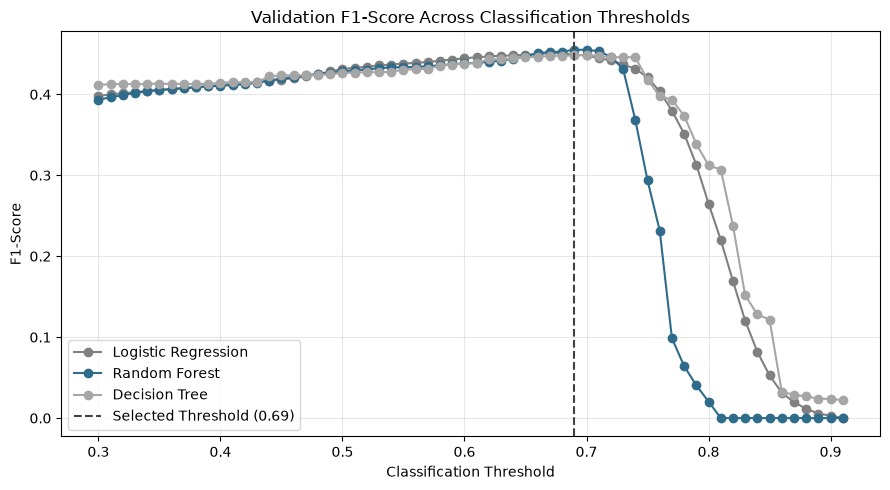

In [110]:
# Prepare validation results for plotting
validation_plot_df = validation_results_df.pivot(
    index="Threshold",
    columns="Model",
    values="F1-Score"
)

plt.figure(figsize=(9, 5))

# Define consistent chart colours
colors = {
    "Logistic Regression": "#808080",
    "Random Forest": "#2F6B8A",
    "Decision Tree": "#A6A6A6"
}

# Plot F1-score across classification thresholds
for model in [
    "Logistic Regression",
    "Random Forest",
    "Decision Tree"
]:
    plt.plot(
        validation_plot_df.index,
        validation_plot_df[model],
        marker="o",
        label=model,
        color=colors[model]
    )

# Highlight the selected Random Forest threshold
plt.axvline(
    x=0.69,
    color="#404040",
    linestyle="--",
    label="Selected Threshold (0.69)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("F1-Score")
plt.title("Validation F1-Score Across Classification Thresholds")
plt.xticks([0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The validation F1-score comparison shows how classification performance changes across different probability thresholds for the three models. Logistic Regression and Random Forest achieve their strongest F1-scores at higher thresholds, while the Decision Tree maintains relatively stable performance across much of the evaluated range.

The Random Forest threshold of 0.69 was selected based on its validation performance, providing a balance between precision and recall. Increasing the threshold further reduces the number of customers classified as potential responders, which can also lead to missing genuine responders.

From a business perspective, the selected threshold supports customer prioritisation while recognising the trade-off between identifying potential responders and avoiding unnecessary campaign contacts. The final threshold should also be considered in relation to campaign costs and expected conversion revenue.

**Model training data usage**

In [94]:
# Refit preprocessing using the complete training partition
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features),
        ("numerical", StandardScaler(), numerical_features),
        ("binary", "passthrough", binary_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Retrain Random Forest using all training records
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Final Random Forest model trained on complete training data.")
print("Training records:", X_train_processed.shape[0])
print("Test records:", X_test_processed.shape[0])

Final Random Forest model trained on complete training data.
Training records: 304887
Test records: 76222


Final Test Evaluation — Random Forest

In [95]:
# Generate final test probabilities
y_test_prob_rf = rf_model.predict_proba(
    X_test_processed
)[:, 1]

# Apply the threshold selected using validation data
best_threshold = 0.69

y_test_pred_rf = (
    y_test_prob_rf >= best_threshold
).astype(int)

# Final evaluation
print("Threshold Used:", best_threshold)

print("Final Test Accuracy:",
      accuracy_score(y_test, y_test_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_rf,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_rf))


Threshold Used: 0.69
Final Test Accuracy: 0.7786334654036893

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.78      0.86     66880
           1       0.33      0.76      0.46      9342

    accuracy                           0.78     76222
   macro avg       0.64      0.77      0.66     76222
weighted avg       0.88      0.78      0.81     76222


Confusion Matrix:
[[52250 14630]
 [ 2243  7099]]


**Final Model Evaluation – Random Forest**

The final Random Forest model was retrained using the complete training partition of 304,887 records and evaluated on the held-out test partition of 76,222 records. Using the selected classification threshold of 0.69, the model achieved an accuracy of 77.86%, precision of 32.67%, recall of 75.99% and an F1-score of approximately 0.46.

The model correctly identified 7,099 of the 9,342 actual responders, demonstrating its ability to capture approximately 76% of potential customers. However, it also classified 14,630 non-responders as potential responders, resulting in a relatively low precision of 32.67%.

From a business perspective, this model can help prioritise customers for vehicle insurance marketing campaigns. However, contacting all predicted responders may result in considerable campaign costs due to false-positive predictions.

The final campaign threshold should therefore be evaluated against the cost of contacting each customer, expected revenue from a successful conversion and the value of acquiring a new customer. If contact costs are high, a higher threshold may be preferable, whereas a lower threshold may be appropriate when capturing more potential responders is the priority.

In [96]:
print("\nROC-AUC Score:",
      roc_auc_score(y_test, y_test_prob_rf))

print("\nPR-AUC Score:",
      average_precision_score(y_test, y_test_prob_rf))


ROC-AUC Score: 0.8526997087163082

PR-AUC Score: 0.35661375817188606


PR-AUC Score: 0.356613758171886 short interpretation
ROC-AUC (0.8527): The model demonstrates good ability to distinguish between responders and non-responders across different classification thresholds.

PR-AUC (0.3566): The score indicates moderate performance in identifying the minority responder class, highlighting the challenge of achieving high precision and recall with imbalanced data.

In [97]:
# Business Impact Analysis

tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred_rf
).ravel()

total_customers = tn + fp + fn + tp
targeted_customers = tp + fp
actual_responders = tp + fn

targeting_rate = targeted_customers / total_customers * 100
responder_capture_rate = tp / actual_responders * 100
target_precision = tp / targeted_customers * 100
contacts_per_responder = targeted_customers / tp

print("BUSINESS IMPACT ANALYSIS")
print("-" * 40)

print(f"Total customers: {total_customers:,}")
print(f"Customers selected for targeting: {targeted_customers:,}")
print(f"Targeting rate: {targeting_rate:.2f}%")
print(f"Actual responders identified: {tp:,}")
print(f"Responder capture rate: {responder_capture_rate:.2f}%")
print(f"Target precision: {target_precision:.2f}%")
print(f"Contacts per identified responder: {contacts_per_responder:.2f}")
print(f"False-positive contacts: {fp:,}")
print(f"Missed potential responders: {fn:,}")


BUSINESS IMPACT ANALYSIS
----------------------------------------
Total customers: 76,222
Customers selected for targeting: 21,729
Targeting rate: 28.51%
Actual responders identified: 7,099
Responder capture rate: 75.99%
Target precision: 32.67%
Contacts per identified responder: 3.06
False-positive contacts: 14,630
Missed potential responders: 2,243


The model selected 21,729 customers (28.51% of the test population) for targeted marketing. It successfully identified 7,099 actual responders, achieving a responder capture rate of approximately 76%. However, the precision of 32.67% indicates that only around one-third of selected customers responded. The campaign would require contacting approximately 3.06 customers to identify one actual responder. Although 14,630 false-positive contacts may increase campaign costs, the model provides an opportunity to focus marketing efforts on a smaller customer segment rather than contacting everyone. It also missed 2,243 potential responders.

The model can improve customer targeting efficiency, but campaign contact costs and expected conversion revenue should be considered when deciding whether the targeting strategy is financially worthwhile.

#### 6.9 Feature Importance

In [99]:
# Get encoded feature names and Random Forest importances
feature_names = preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Importance": importances
})

# Map encoded features to original feature groups
importance_df["Feature"] = importance_df["Encoded_Feature"].apply(
    lambda name: next(
        (
            col for col in categorical_features + numerical_features + binary_features
            if name.split("__")[-1] == col
            or name.split("__")[-1].startswith(col + "_")
        ),
        name.split("__")[-1]
    )
)

# Aggregate importance by original feature
feature_importance = (
    importance_df
    .groupby("Feature")["Importance"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

feature_importance.head(10).round(4)

,Feature,Importance
0,Vehicle_Damage,0.4939
1,Previously_Insured,0.2183
2,Policy_Sales_Channel,0.1040
3,Vehicle_Age,0.0837
4,Age,0.0637
5,Region_Code,0.0221
6,Annual_Premium,0.0056
7,Vintage,0.0042
8,Gender,0.0040
9,Driving_License,0.0005


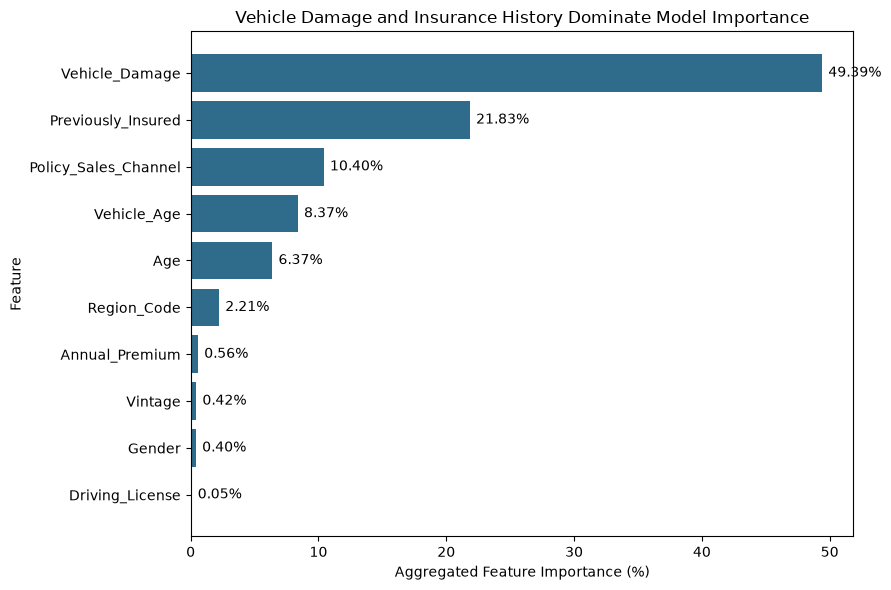

In [108]:
plt.figure(figsize=(9, 6))

bars = plt.barh(
    top_features["Feature"],
    top_features["Importance"] * 100,
    color="#2F6B8A"
)

plt.xlabel("Aggregated Feature Importance (%)")
plt.ylabel("Feature")
plt.title("Vehicle Damage and Insurance History Dominate Model Importance")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

plt.tight_layout()
plt.show()


The feature importance analysis shows that Vehicle_Damage (49.39%) is the most influential feature in the Random Forest model, followed by Previously_Insured (21.83%). Together, these two features account for approximately 71.22% of the model's total feature importance. Policy_Sales_Channel (10.40%), Vehicle_Age (8.37%) and Age (6.37%) also contribute to the model's predictions. In contrast, Annual_Premium, Vintage, Gender and Driving_License have relatively low importance.

Business implication: Vehicle damage history and previous insurance status are the strongest predictive factors in this model and may help prioritise customers for targeted marketing campaigns.

Interpretation and Limitation

Vehicle damage and previous insurance status emerged as the most influential features in the Random Forest model, together accounting for approximately 71.22% of the aggregated feature importance.

These results suggest that vehicle damage history and previous insurance status are important factors in the model's predictions. However, the importance values are based on impurity reduction and should be interpreted as model-specific indicators rather than causal effects. They may also be affected by feature characteristics and correlations. Further validation using permutation importance could provide an additional perspective on feature relevance.

# 7. Final Project Conclusion and Business Recommendations

## 7.1 Project Conclusion

This project aimed to identify existing customers who are more likely to respond positively to a vehicle insurance cross-selling offer. The analysis was conducted using 381,109 customer records containing demographic, vehicle-related and policy-related information.

An end-to-end analytical workflow was developed, covering data understanding, data cleaning, exploratory data analysis (EDA), feature engineering, statistical analysis and predictive modelling.

The exploratory analysis identified several customer characteristics associated with positive responses, particularly vehicle damage history, previous insurance status, vehicle age, customer age and policy sales channel. Statistical testing supported the associations between customer response and the categorical features examined. Annual Premium also showed a statistically significant difference between responders and non-responders, although its effect size was small.

Three classification algorithms were evaluated: Logistic Regression, Random Forest and Decision Tree. Their performance was compared using validation data. Random Forest was selected as the final model based on its overall performance. An expanded threshold comparison was conducted using validation data, and a classification threshold of 0.69 achieved the highest F1-score among the evaluated combinations, with a validation F1-score of 0.4551.

Following threshold selection, the Random Forest model was retrained using the complete training partition of 304,887 records and evaluated on the held-out test partition of 76,222 records. At the selected classification threshold of 0.69, the final model achieved the following results:

| Evaluation Metric | Test Result |
|---|---:|
| Accuracy | 77.86% |
| Precision (Positive Class) | 32.67% |
| Recall (Positive Class) | 75.99% |
| F1-score (Positive Class) | 0.46 |
| ROC-AUC | 0.8527 |
| Average Precision (PR-AUC) | 0.3566 |

The ROC-AUC score of 0.8527 indicates that the model demonstrates a strong ability to distinguish between potential responders and non-responders based on predicted probabilities. The Average Precision score of 0.3566 provides additional insight into the precision-recall trade-off, which is particularly relevant given the imbalance in the target variable.

The results demonstrate that the model can identify a substantial proportion of potential responders. However, its relatively low precision indicates that a considerable number of customers predicted as responders may not respond positively.

Overall, the project demonstrates the potential of machine learning techniques to support customer segmentation and targeted marketing activities. Nevertheless, the model should be considered a decision-support tool rather than a guarantee of customer response. Its practical effectiveness will depend on campaign costs, conversion revenue and further evaluation using real campaign outcomes.

## 7.2 Key Business Findings

The exploratory analysis revealed several customer response patterns that may support customer segmentation and marketing campaign planning.

**1. Vehicle Damage**

Customers with previously damaged vehicles recorded a response rate of 23.77%, compared with 0.52% among customers without previous vehicle damage. This indicates a strong association between vehicle damage history and customer response in the analysed dataset.

**2. Previous Insurance Status**

Customers without previous vehicle insurance recorded a response rate of 22.55%, compared with 0.09% among customers who were previously insured. This suggests that previous insurance status is an important characteristic for understanding customer response patterns.

**3. Vehicle Age**

Customers with vehicles older than two years showed the highest observed response rate at 29.37%. However, this segment represented a comparatively smaller customer group, which should be considered when planning marketing activities.

**4. Customer Age**

Customers aged 36–45 recorded the highest response rate among the analysed age groups, at 21.54%. This segment may be worth further investigation when developing customer targeting strategies.

**5. Policy Sales Channel**

Response rates varied across policy sales channels. Among the ten most frequent channels, Channel 163 recorded the highest response rate at 30.42%. This suggests that channel-level performance should be investigated further while considering both response rates and customer volumes.

**6. Annual Premium**

Responders had a higher median annual premium (33,002) than non-responders (31,504). Although the difference was statistically significant, the effect size was small, indicating limited practical separation between the two groups based on annual premium alone.

## 7.3 Model Interpretability and Feature Importance

The Random Forest feature importance analysis identified Vehicle_Damage (49.39%) as the most influential feature, followed by Previously_Insured (21.83%). Together, these two features accounted for approximately 71.22% of the aggregated feature importance.

Other contributing features included Policy_Sales_Channel (10.40%), Vehicle_Age (8.37%) and Age (6.37%). In comparison, Region_Code, Annual_Premium, Vintage, Gender and Driving_License had relatively lower importance.

These findings suggest that vehicle damage history and previous insurance status are particularly relevant to the model's predictions. However, the importance values are based on impurity reduction and should be interpreted as model-specific indicators rather than causal effects. They may also be affected by feature characteristics and correlations.

## 7.4 Business Recommendations

Based on the exploratory findings and final model evaluation, the following recommendations are proposed:

**1. Prioritise Data-Driven Customer Segmentation**

Use customer characteristics such as vehicle damage history, previous insurance status, vehicle age and customer age to support the identification of potentially interested customers. These characteristics can help marketing teams develop more focused customer segments.

**2. Improve Targeted Marketing Campaigns**

Use the Random Forest model to support customer prioritisation rather than contacting the entire customer population. The selected threshold of 0.69 identified approximately 28.51% of the test population for targeting while capturing approximately 75.99% actual responders.

**3. Consider Campaign Contact Costs**

The model achieved a precision of 32.67%, meaning that a substantial proportion of selected customers did not respond. Before implementing the model, the organisation should evaluate contact costs, expected conversion revenue and the value of a successful customer acquisition.

**4. Evaluate Marketing Channel Performance**

Investigate differences in response rates across policy sales channels, particularly channels showing relatively high response rates. Marketing resources can then be allocated based on both response rates and customer volumes.

**5. Monitor and Improve Model Performance**

Evaluate the model using future campaign results and monitor changes in precision, recall and conversion rates. Periodic model evaluation and retraining may help maintain predictive performance as customer behaviour changes.

**6. Conduct Further Model Validation**

Further validation using permutation importance, probability calibration and independent future campaign data could provide additional evidence about feature relevance and model reliability.

## 7.5 Limitations and Future Scope

Despite the useful findings, this project has several limitations.

First, the target variable is imbalanced, with a considerably smaller proportion of positive responses than negative responses. This makes identifying potential responders more challenging and affects the interpretation of accuracy and precision.

Second, the final model achieved relatively low precision, indicating that many customers classified as potential responders may not convert. Therefore, the model's predictions should support, rather than replace, marketing decisions.

Third, the feature importance values represent predictive relationships and do not establish causal relationships between customer characteristics and response behaviour.

Exploratory data analysis and statistical testing were conducted on the full dataset before the train-test split. Although the test partition was excluded from model fitting and preprocessing, it was not completely isolated from the exploratory analysis. Therefore, the final test performance should be interpreted with this methodological consideration in mind.

Multiple statistical tests were conducted; however, no formal multiple-comparison correction, such as the Bonferroni correction, was applied. Therefore, the possibility of an increased family-wise Type I error rate should be considered when interpreting the statistical findings.

Finally, the model was evaluated using a held-out test partition. Further evaluation using independent future campaign data would provide stronger evidence of its performance in a real business environment.

Future work could explore hyperparameter optimisation, probability calibration, alternative classification thresholds and additional customer-related features. Incorporating actual campaign costs and conversion revenue into threshold selection could also help determine a more commercially appropriate targeting strategy.

In conclusion, this project demonstrates how exploratory data analysis, statistical techniques and machine learning can be combined to identify customer response patterns and support more focused vehicle insurance cross-selling activities.